## Load and check data

In [2]:
import pandas as pd

In [3]:
df = pd.read_csv('../data/cleaned/books_cleaned.csv')

In [4]:
print(f"dataset shape: {df.shape}")
print(f"Name of the columns: {df.columns.tolist()}")
print(f"Head (first 5 rows):")
df.head()

dataset shape: (175, 8)
Name of the columns: ['title', 'category', 'book_url', 'image_url', 'description', 'image_path', 'title_length', 'description_length']
Head (first 5 rows):


,title,category,book_url,image_url,description,image_path,title_length,description_length
0,Soumission,Fiction,https://books.toscrape.com/catalogue/soumissio...,https://books.toscrape.com/media/cache/3e/ef/3...,"Dans une France assez proche de la nôtre, un h...",images/book_0.jpg,10,1093
1,Private Paris (Private #10),Fiction,https://books.toscrape.com/catalogue/private-p...,https://books.toscrape.com/media/cache/9d/05/9...,Paris is burning--and only Private's Jack Morg...,images/book_1.jpg,27,1131
2,"We Love You, Charlie Freeman",Fiction,https://books.toscrape.com/catalogue/we-love-y...,https://books.toscrape.com/media/cache/5f/15/5...,"The Freeman family--Charles, Laurel, and their...",images/book_2.jpg,28,1491
3,Thirst,Fiction,https://books.toscrape.com/catalogue/thirst_94...,https://books.toscrape.com/media/cache/c4/0a/c...,"On a searing summer Friday, Eddie Chapman has ...",images/book_3.jpg,6,1451
4,The Murder That Never Was (Forensic Instincts #5),Fiction,https://books.toscrape.com/catalogue/the-murde...,https://books.toscrape.com/media/cache/dc/44/d...,"Given the opportunity, would you assume someon...",images/book_4.jpg,49,1843


In [5]:
print("class distribution:")
print(df['category'].value_counts())

class distribution:
category
Nonfiction    110
Fiction        65
Name: count, dtype: int64


## Preparing Data. (For our case, we are using description as feature)

In [6]:
x = df['description']
y = df['category']

In [7]:
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

print(f"no of classes: {label_encoder.classes_}")
print(f"feature shape: {x.shape}")
print(f"target shape: {y_encoded.shape}")

no of classes: ['Fiction' 'Nonfiction']
feature shape: (175,)
target shape: (175,)


## Preparing train-test split

In [8]:
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(
    x,
    y_encoded,
    test_size=0.2,
    random_state=42,
    stratify=y_encoded
)

In [9]:
print(f"size of the training set: {len(x_train)}")
print(f"size of the testing set: {len(x_test)}")

print(f"set distribution (training set):")
print(pd.Series(y_train).value_counts())
print(f"set distribution (testing set):")
print(pd.Series(y_test).value_counts())

size of the training set: 140
size of the testing set: 35
set distribution (training set):
1    88
0    52
Name: count, dtype: int64
set distribution (testing set):
1    22
0    13
Name: count, dtype: int64


## Extracting feature using TF-IDF

In [10]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf_vectorizer = TfidfVectorizer(
    max_features=100,
    min_df=2,
    max_df=0.8,
    ngram_range=(1,2),
    stop_words='english'
)

x_train_tfidf=tfidf_vectorizer.fit_transform(x_train)
x_test_tfidf=tfidf_vectorizer.transform(x_test)

In [11]:
print(f"training features shape: {x_train_tfidf.shape}")
print(f"test features shape: {x_test_tfidf.shape}")
print(f"vocabulary size: {len(tfidf_vectorizer.vocabulary_)}")

training features shape: (140, 100)
test features shape: (35, 100)
vocabulary size: 100


## Train Multinomial Naive Bayes

In [12]:
from sklearn.naive_bayes import MultinomialNB

nb_model = MultinomialNB()
nb_model.fit(x_train_tfidf, y_train)

y_pred_nb = nb_model.predict(x_test_tfidf)

In [13]:
from sklearn.metrics import (
    accuracy_score, 
    classification_report, 
    f1_score,
    precision_score,
    recall_score
)

print(f"Accuracy: {accuracy_score(y_test, y_pred_nb):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_nb):.4f}")
print(f"Recall: {recall_score(y_test, y_pred_nb):.4f}")
print(f"F1-score: {f1_score(y_test, y_pred_nb):.4f}")

print("classification report:")
print(classification_report(
    y_test,
    y_pred_nb,
    target_names=label_encoder.classes_
))

Accuracy: 0.6857
Precision: 0.7037
Recall: 0.8636
F1-score: 0.7755
classification report:
              precision    recall  f1-score   support

     Fiction       0.62      0.38      0.48        13
  Nonfiction       0.70      0.86      0.78        22

    accuracy                           0.69        35
   macro avg       0.66      0.62      0.63        35
weighted avg       0.67      0.69      0.66        35



## Train Logistic Regression

In [14]:
from sklearn.linear_model import LogisticRegression

lr_model = LogisticRegression(
    max_iter=50,
    random_state=42
)

lr_model.fit(x_train_tfidf, y_train)

y_pred_lr = lr_model.predict(x_test_tfidf)

In [15]:
print(f"Accuracy: {accuracy_score(y_test, y_pred_lr):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_lr):.4f}")
print(f"Recall: {recall_score(y_test, y_pred_lr):.4f}")
print(f"F1-Score: {f1_score(y_test, y_pred_lr):.4f}")

print("classification report:")
print(classification_report(
    y_test,
    y_pred_lr,
    target_names=label_encoder.classes_
))

Accuracy: 0.7143
Precision: 0.7000
Recall: 0.9545
F1-Score: 0.8077
classification report:
              precision    recall  f1-score   support

     Fiction       0.80      0.31      0.44        13
  Nonfiction       0.70      0.95      0.81        22

    accuracy                           0.71        35
   macro avg       0.75      0.63      0.63        35
weighted avg       0.74      0.71      0.67        35



## Train Random Forest

In [16]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=1
)

rf_model.fit(x_train_tfidf, y_train)

y_pred_rf = rf_model.predict(x_test_tfidf)

In [17]:
print(f"Accuracy: {accuracy_score(y_test, y_pred_rf):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_rf):.4f}")
print(f"Recall: {recall_score(y_test, y_pred_rf):.4f}")
print(f"F1-Score: {f1_score(y_test, y_pred_rf):.4f}")

print("Classification Report:")
print(classification_report(
    y_test,
    y_pred_rf,
    target_names=label_encoder.classes_
))

Accuracy: 0.7429
Precision: 0.7407
Recall: 0.9091
F1-Score: 0.8163
Classification Report:
              precision    recall  f1-score   support

     Fiction       0.75      0.46      0.57        13
  Nonfiction       0.74      0.91      0.82        22

    accuracy                           0.74        35
   macro avg       0.75      0.69      0.69        35
weighted avg       0.74      0.74      0.73        35



## Train Support Vector Machine

In [18]:
from sklearn.svm import SVC

svm_model = SVC(
    kernel = 'linear',
    random_state = 42
)

svm_model.fit(x_train_tfidf, y_train)

y_pred_svm = svm_model.predict(x_test_tfidf)

In [19]:
print(f"Accuracy: {accuracy_score(y_test, y_pred_svm):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_svm):.4f}")
print(f"Recall: {recall_score(y_test, y_pred_svm):.4f}")
print(f"F1-Score: {f1_score(y_test, y_pred_svm):.4f}")

print("Classification Report:")
print(classification_report(
    y_test,
    y_pred_svm,
    target_names=label_encoder.classes_
))

Accuracy: 0.6571
Precision: 0.6786
Recall: 0.8636
F1-Score: 0.7600
Classification Report:
              precision    recall  f1-score   support

     Fiction       0.57      0.31      0.40        13
  Nonfiction       0.68      0.86      0.76        22

    accuracy                           0.66        35
   macro avg       0.62      0.59      0.58        35
weighted avg       0.64      0.66      0.63        35



## Compare all the models

In [20]:
results = {
    'Model': [
        'Naive Bayes',
        'Logistic Regression',
        'Random Forest',
        'SVM'
    ],
    'Accuracy': [
        accuracy_score(y_test, y_pred_nb),
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_rf),
        accuracy_score(y_test, y_pred_svm)
    ],
    'Precision': [
        precision_score(y_test, y_pred_nb),
        precision_score(y_test, y_pred_lr),
        precision_score(y_test, y_pred_rf),
        precision_score(y_test, y_pred_svm)
    ],
    'Recall': [
        recall_score(y_test, y_pred_nb),
        recall_score(y_test, y_pred_lr),
        recall_score(y_test, y_pred_rf),
        recall_score(y_test, y_pred_svm)
    ],
    'F1-Score': [
        f1_score(y_test, y_pred_nb),
        f1_score(y_test, y_pred_lr),
        f1_score(y_test, y_pred_rf),
        f1_score(y_test, y_pred_svm)
    ]
}

results_df = pd.DataFrame(results)
display(results_df)

,Model,Accuracy,Precision,Recall,F1-Score
0,Naive Bayes,0.685714,0.703704,0.863636,0.775510
1,Logistic Regression,0.714286,0.700000,0.954545,0.807692
2,Random Forest,0.742857,0.740741,0.909091,0.816327
3,SVM,0.657143,0.678571,0.863636,0.760000


## Result and confusion matrix for the highest accuracy model (Random Forest)

Accuracy: 0.7429
Precision: 0.7407
Recall: 0.9091
F1-Score: 0.8163


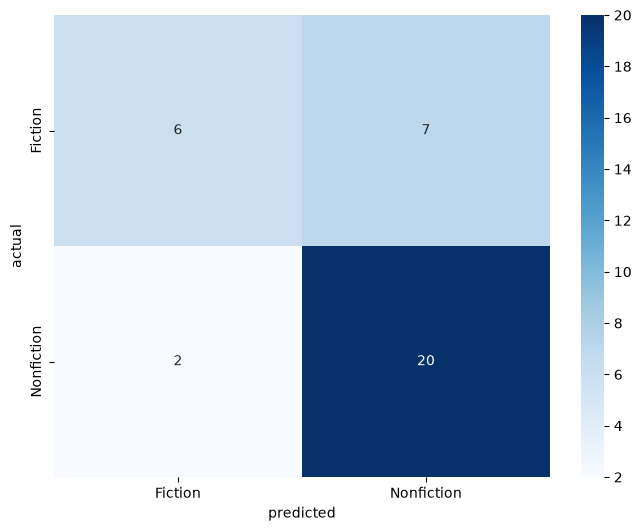

In [21]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

print(f"Accuracy: {accuracy_score(y_test, y_pred_rf):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_rf):.4f}")
print(f"Recall: {recall_score(y_test, y_pred_rf):.4f}")
print(f"F1-Score: {f1_score(y_test, y_pred_rf):.4f}")

cm = confusion_matrix(y_test, y_pred_rf)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.ylabel('actual')
plt.xlabel('predicted')

plt.show()